### Load the dataset

In [1]:
# Import the required library
import pandas as pd

# Define the dataset path
data_path = "../Mall_Customers.csv"

# Load the dataset
df = pd.read_csv(data_path)

# Display the first five rows
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [2]:
# Inspect the dataset

# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display data types and non-null counts
print("\nDataset information:")
df.info()

# Display summary statistics
print("\nSummary statistics:")
df.describe(include="all")

Dataset shape: (200, 5)

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB

Summary statistics:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000


### Data Quality Checks

In [3]:
# Check missing values in each column
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [4]:
# Count duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [5]:
# Count unique values in each column
df.nunique()

CustomerID                200
Gender                      2
Age                        51
Annual Income (k$)         64
Spending Score (1-100)     84
dtype: int64

In [6]:
# Numerical columns only
numerical_columns = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

# Summary statistics
df[numerical_columns].describe()

,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


### Exploratory Data Analysis (EDA)

In [7]:
# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent plotting style
sns.set_theme(style="whitegrid")

print("Visualization libraries imported successfully!")

Visualization libraries imported successfully!


Gender
Female    112
Male       88
Name: count, dtype: int64


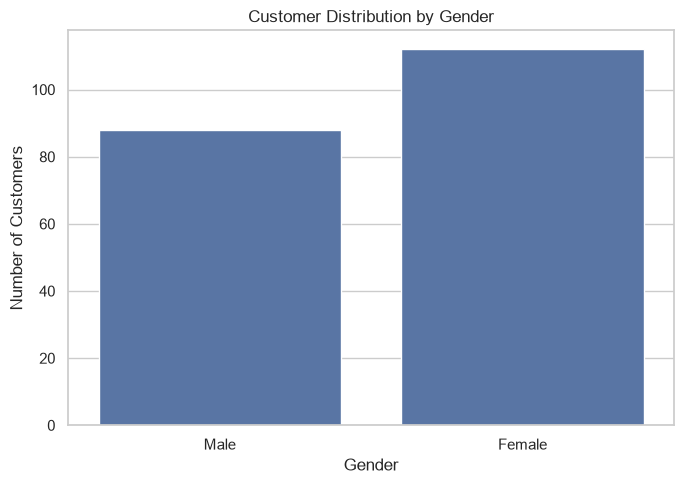

In [8]:
# Count customers by gender
gender_counts = df["Gender"].value_counts()

print(gender_counts)

# Visualize gender distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Gender"
)

plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

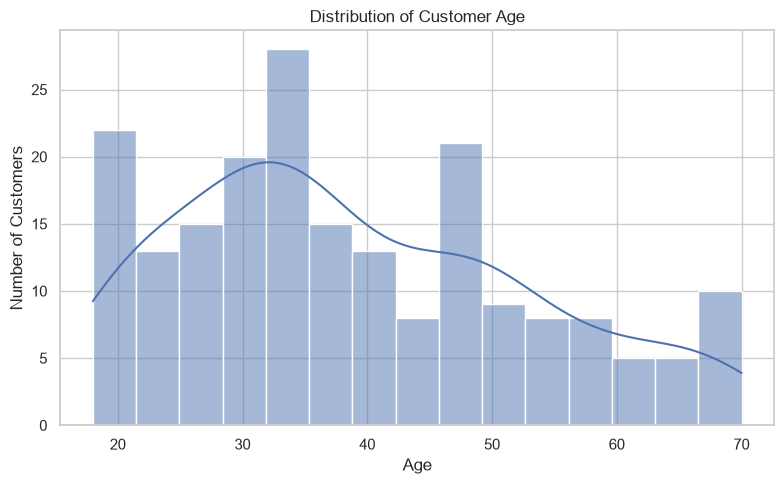

In [9]:
# Visualize age distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=15,
    kde=True
)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

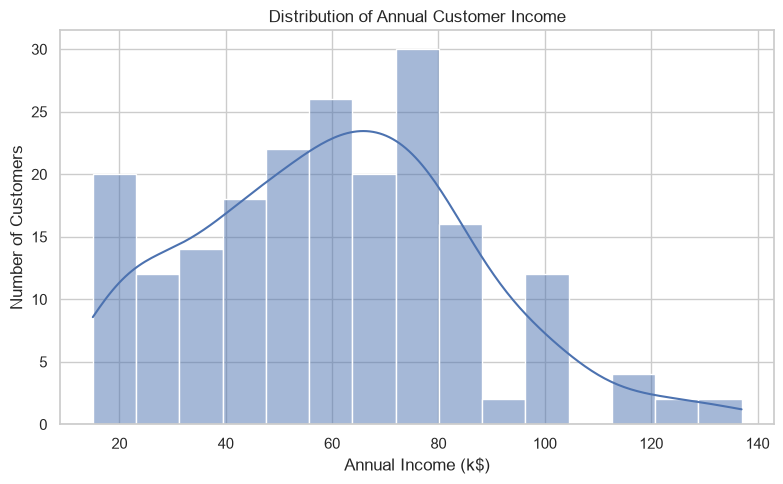

In [10]:
# Visualize annual income distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Annual Income (k$)",
    bins=15,
    kde=True
)

plt.title("Distribution of Annual Customer Income")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

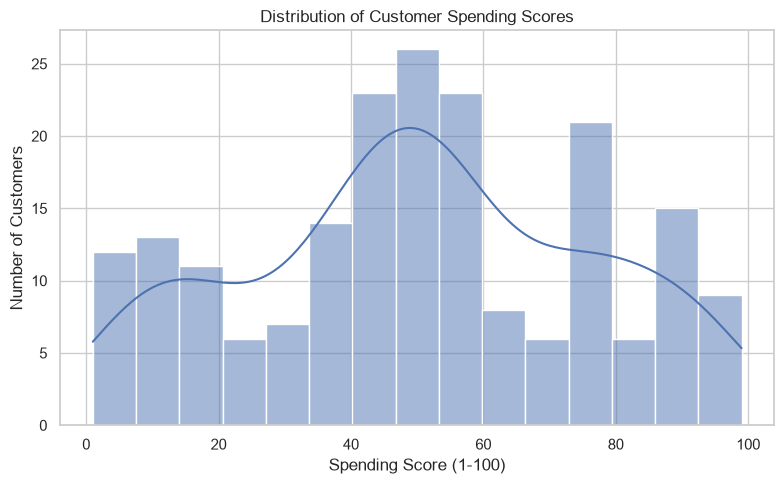

In [11]:
# Visualize spending score distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Spending Score (1-100)",
    bins=15,
    kde=True
)

plt.title("Distribution of Customer Spending Scores")
plt.xlabel("Spending Score (1-100)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Feature Selection

In [12]:
# Select features for customer segmentation
FEATURES = [
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[FEATURES].copy()

print("Clustering dataset shape:", X.shape)
X.head()

Clustering dataset shape: (200, 2)


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


### Feature Scaling

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled dataset shape:", X_scaled.shape)

Scaled dataset shape: (200, 2)


### K-Means Clustering

#### 1. Find the optimal number of clusters

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

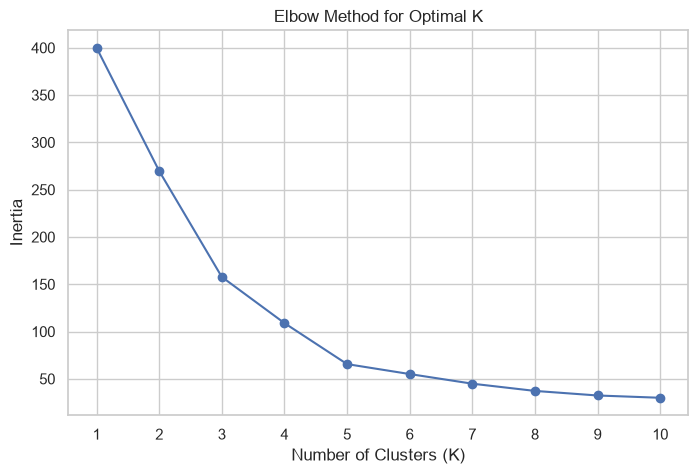

In [14]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.xticks(k_values)
plt.show()

#### 2. Fit the K-Means model

In [15]:
# Train the final K-Means model
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Assign a cluster to each customer
df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

# Check the number of customers in each cluster
df["KMeans_Cluster"].value_counts().sort_index()

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


KMeans_Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

- n_clusters=5: Creates five customer groups.
- random_state=42: Makes the results reproducible.
- n_init=10: Tries different initial centroid positions and retains the best solution.
- fit_predict(): Learns the clusters and assigns each customer a cluster label from 0 to 4.

#### 3. Visualize the customer segments

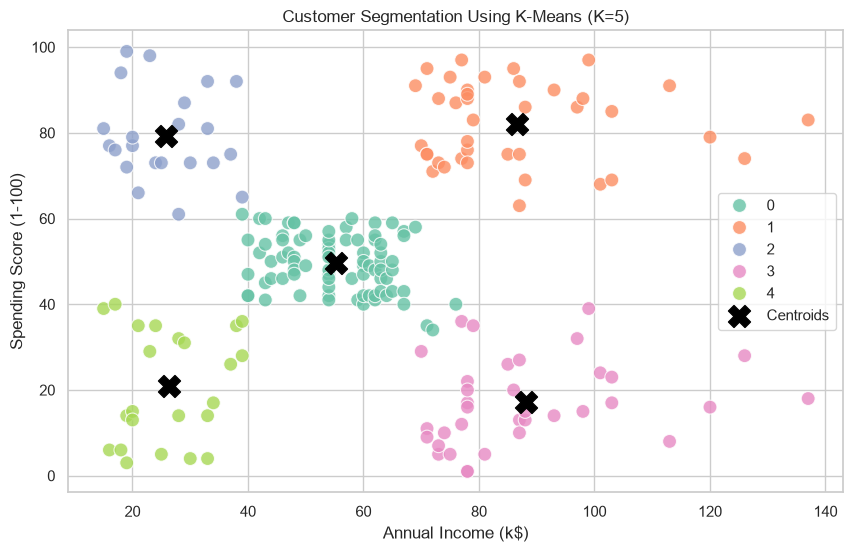

In [16]:
# Get the cluster centers in the original feature scale
centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="KMeans_Cluster",
    palette="Set2",
    s=100,
    alpha=0.8
)

# Plot the cluster centers
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Centroids"
)

plt.title("Customer Segmentation Using K-Means (K=5)")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.show()

#### 4. Profile the clusters

In [17]:
cluster_profile = df.groupby("KMeans_Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Avg_Annual_Income=("Annual Income (k$)", "mean"),
    Avg_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

cluster_profile

,Customer_Count,Avg_Annual_Income,Avg_Spending_Score
KMeans_Cluster,,,
0,81,55.30,49.52
1,39,86.54,82.13
2,22,25.73,79.36
3,35,88.20,17.11
4,23,26.30,20.91


### DBSCAN

In [18]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.3, min_samples=5)

df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

df["DBSCAN_Cluster"].value_counts().sort_index()

DBSCAN_Cluster
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64

- 7 clusters: Labels 0 through 6.
- 35 noise points: -1, representing approximately 17.5% of customers.
- Largest cluster: Cluster 3, with 88 customers.
- Parameter: eps=0.3, min_samples=5

The choice of eps strongly affects the number of clusters and noise points..

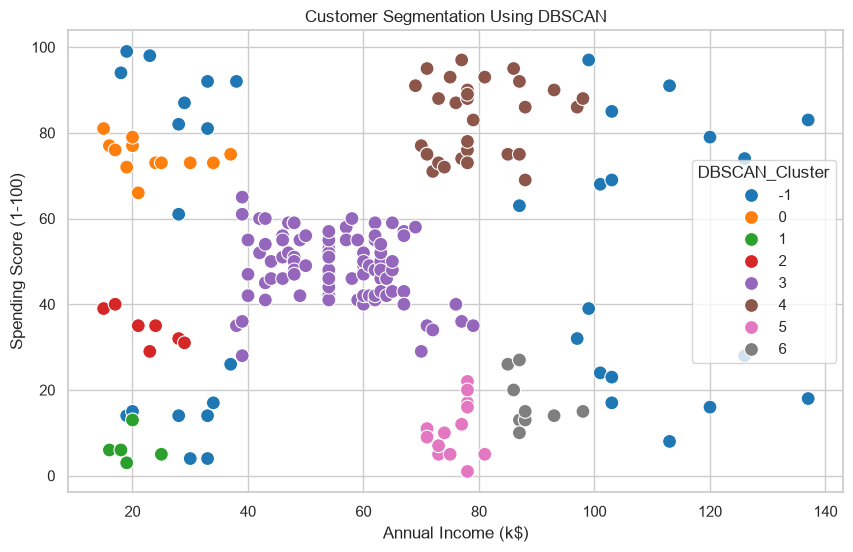

In [19]:
# Visualize DBSCAN results
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="DBSCAN_Cluster",
    palette="tab10",
    s=100
)

plt.title("Customer Segmentation Using DBSCAN")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()

### Evaluation 

In [21]:
# Compare K-Means and DBSCAN
from sklearn.metrics import silhouette_score

kmeans_silhouette = silhouette_score(X_scaled, df["KMeans_Cluster"])

# Silhouette score for DBSCAN, excluding noise points
dbscan_mask = df["DBSCAN_Cluster"] != -1
X_dbscan = X_scaled[dbscan_mask]
labels_dbscan = df.loc[dbscan_mask, "DBSCAN_Cluster"]

if labels_dbscan.nunique() >= 2:
    dbscan_silhouette = silhouette_score(X_dbscan, labels_dbscan)
else:
    dbscan_silhouette = None

print(f"K-Means Silhouette Score: {kmeans_silhouette:.3f}")
print(f"DBSCAN Silhouette Score (excluding noise): {dbscan_silhouette}")

K-Means Silhouette Score: 0.555
DBSCAN Silhouette Score (excluding noise): 0.5243276105881419


### Business Interpretation 

| Cluster | Customers | Avg. Income (k$) | Avg. Spending Score | Customer Segment                 | Potential Business Strategy                                                 |
| ------- | --------: | ---------------: | ------------------: | -------------------------------- | --------------------------------------------------------------------------- |
| **0**   |        81 |            55.30 |               49.52 | Average Income, Average Spending | Loyalty programs, personalized recommendations, and targeted promotions.    |
| **1**   |        39 |            86.54 |               82.13 | High Income, High Spending       | Premium products, exclusive offers, and VIP loyalty benefits.               |
| **2**   |        22 |            25.73 |               79.36 | Low Income, High Spending        | Affordable premium options, rewards, and value-focused promotions.          |
| **3**   |        35 |            88.20 |               17.11 | High Income, Low Spending        | Understand purchase barriers and test personalized product recommendations. |
| **4**   |        23 |            26.30 |               20.91 | Low Income, Low Spending         | Budget-friendly products, discounts, and essential-product promotions.      |
